# Klasifikasi Audio Berisik vs Non-Berisik

**Tujuan:** membangun model klasifikasi biner untuk membedakan rekaman **berisik** (ada gangguan suara latar) dan **non-berisik** (relatif sunyi), dengan target akurasi **> 90%** pada data uji.

**Dataset:** `psd-audio/berisik` (101 file) dan `psd-audio/non-berisik` (100 file), format MP3, durasi ±30 detik per file.

**Pipeline:**
1. Audit kualitas data (duplikat file & label bertentangan)
2. Ekstraksi fitur audio (MFCC, spektral, noise-floor, RMS)
3. Pemodelan & tuning (SVM RBF sebagai model utama)
4. Evaluasi (holdout test, stratified 5-fold CV berulang, confusion matrix)
5. Simpan model & fungsi inferensi

## Business Understanding

### Latar Belakang
Rekaman audio dapat mengandung gangguan suara latar yang menurunkan kualitas informasi dan mengganggu proses analisis maupun komunikasi. Karena itu, diperlukan sistem yang dapat mengidentifikasi apakah sebuah rekaman termasuk **berisik** atau **non-berisik** secara otomatis.

### Tujuan Bisnis
- Membantu pengguna melakukan pemeriksaan kualitas rekaman audio secara cepat dan konsisten.
- Mengurangi ketergantungan pada pemeriksaan manual yang subjektif dan memerlukan waktu.
- Menyediakan dasar untuk proses lanjutan, seperti penyaringan audio, peningkatan kualitas suara, atau pengambilan keputusan berbasis kualitas rekaman.

### Tujuan Analitik
Membangun model klasifikasi biner dengan memanfaatkan karakteristik audio, seperti MFCC, fitur spektral, noise floor, dan RMS, untuk memprediksi label **berisik** dan **non-berisik**. Model ditargetkan mencapai akurasi di atas 90% pada data uji, dengan evaluasi tambahan menggunakan cross-validation dan confusion matrix.

### Pemangku Kepentingan dan Pengguna
Solusi ini dapat digunakan oleh pengembang aplikasi audio, analis data, peneliti pengolahan suara, maupun pengguna umum yang ingin memeriksa kualitas rekaman sebelum digunakan lebih lanjut.

### Kriteria Keberhasilan
Keberhasilan solusi diukur dari performa klasifikasi yang baik, kestabilan hasil evaluasi, serta tersedianya aplikasi yang dapat digunakan untuk melakukan prediksi pada file audio baru.

## Hasil Deployment

Model telah di-deploy dalam bentuk aplikasi web yang dapat digunakan untuk menguji klasifikasi audio secara langsung:

**Aplikasi:** [silent-lab.vercel.app](https://silent-lab.vercel.app)

Aplikasi deployment tersebut menjadi antarmuka penggunaan model, sedangkan notebook ini mendokumentasikan proses pemahaman masalah, persiapan data, ekstraksi fitur, pelatihan, dan evaluasi model.


## Data Understanding

Dataset proyek ini berisi rekaman audio berformat MP3 yang dikelompokkan ke dalam dua kelas:

| Label | Makna | Jumlah awal |
|---|---|---:|
| `berisik` | Rekaman dengan gangguan suara latar atau *noise floor* yang relatif tinggi | 101 file |
| `non-berisik` | Rekaman yang relatif sunyi dengan gangguan latar lebih rendah | 100 file |

Setiap file dibaca sebagai sinyal digital menggunakan `librosa`. Informasi yang diperiksa meliputi nama file, label kelas, durasi, sampling rate, jumlah sampel, dan checksum MD5. Pemeriksaan ini penting untuk memastikan file dapat dibaca serta mengetahui apakah terdapat file duplikat atau durasi yang tidak seragam.

Target prediksi adalah label biner `berisik` dan `non-berisik`. Karena durasi rekaman dapat berbeda, model tidak langsung menggunakan seluruh sampel audio sebagai input. Audio terlebih dahulu dibagi menjadi frame, kemudian setiap frame diringkas menjadi fitur statistik sehingga setiap file direpresentasikan oleh satu baris data fitur.

**Unit analisis:** satu file audio.  
**Target:** `label`.  
**Prediktor:** fitur energi, spektral, MFCC, noise-floor, dan spectral contrast.


## Setup

### Dependensi yang Dibutuhkan

Notebook ini membutuhkan beberapa library Python untuk membaca audio, mengekstraksi fitur, membuat visualisasi, dan melatih model machine learning.

| Paket | Kegunaan |
|---|---|
| `librosa` | Membaca audio dan mengekstraksi fitur audio |
| `soundfile` | Backend pembacaan file audio |
| `numpy` | Operasi numerik |
| `scipy` | Operasi ilmiah dan dependensi pemrosesan audio/model |
| `pandas` | Pengolahan tabel data |
| `matplotlib` dan `seaborn` | Visualisasi |
| `scikit-learn` | Fitur seleksi, cross-validation, tuning, dan model klasifikasi |
| `joblib` | Menyimpan dan memuat model |

Cell berikut menggunakan `%pip` agar paket dipasang pada environment/kernel Python yang sedang digunakan notebook. Setelah instalasi selesai, bila kernel meminta restart, pilih **Restart Kernel** lalu jalankan notebook kembali dari awal.

> **Catatan MP3:** kode memiliki fallback ke perintah `ffmpeg` untuk file yang tidak dapat dibaca langsung oleh `soundfile`. Karena FFmpeg adalah aplikasi sistem, bukan paket Python, instal juga FFmpeg dan pastikan perintah `ffmpeg` tersedia di PATH Windows. Paket `%pip install ffmpeg-python` saja tidak memasang executable FFmpeg.


## Reproducibility

Agar hasil notebook dapat diulang, gunakan langkah berikut:

1. Pilih Python environment/kernel yang sama untuk seluruh cell.
2. Jalankan cell instalasi pada bagian **Setup**, kemudian restart kernel jika diminta.
3. Jalankan semua cell secara berurutan dari atas sampai bawah, bukan hanya cell modeling.
4. Pastikan folder dataset berada pada path yang dikenali oleh `BASE_DIR`.
5. Pertahankan `RANDOM_STATE = 42` untuk split data dan konfigurasi acak utama.
6. Catat versi library yang digunakan, terutama `librosa`, `numpy`, `scipy`, `pandas`, dan `scikit-learn`.
7. Simpan output fitur dan model setelah eksekusi selesai.

Untuk memeriksa versi library pada environment aktif:

```python
import sklearn
import scipy

print('librosa:', librosa.__version__)
print('numpy:', np.__version__)
print('scipy:', scipy.__version__)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
```

Hasil angka pada catatan harus diambil dari eksekusi terakhir setelah seluruh notebook dijalankan ulang, karena perubahan dataset, environment, atau konfigurasi dapat mengubah jumlah data dan skor evaluasi.


In [4]:
%pip install -q \
    librosa \
    soundfile \
    numpy \
    scipy \
    pandas \
    matplotlib \
    seaborn \
    scikit-learn \
    joblib


Note: you may need to restart the kernel to use updated packages.


### Penjelasan Instalasi
Cell ini memasang seluruh dependensi Python yang dibutuhkan notebook, yaitu library pemrosesan audio, pengolahan data, visualisasi, machine learning, dan penyimpanan model. `%pip` digunakan agar instalasi masuk ke environment kernel yang sedang aktif. Setelah instalasi atau restart kernel, cell-cell berikut perlu dijalankan kembali dari atas.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import hashlib
import subprocess
from pathlib import Path

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedGroupKFold, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (12, 5)
RANDOM_STATE = 42

BASE_DIR = Path('../psd-audio') if Path('../psd-audio').exists() else (Path('..') if (Path('..') / 'berisik').exists() else Path('.'))
KELAS = ['berisik', 'non-berisik']
PALETTE = {'berisik': '#e74c3c', 'non-berisik': '#2ecc71'}
SR = 22050
print('librosa', librosa.__version__)


librosa 0.11.0


### Penjelasan Setup dan Import
Cell ini mengimpor library yang digunakan pada seluruh analisis. `librosa` menangani pembacaan dan ekstraksi fitur audio, `pandas` dan `numpy` mengolah data, `matplotlib` dan `seaborn` membuat visualisasi, sedangkan `scikit-learn` menyediakan model, pipeline, seleksi fitur, cross-validation, dan evaluasi. Konstanta `RANDOM_STATE=42`, sampling rate 22.050 Hz, nama kelas, serta warna visualisasi juga ditetapkan di sini agar proses konsisten.


## Inventaris Data & EDA

Cek jumlah file, durasi, dan distribusi kelas. Durasi penting: file berisik ada yang jauh lebih panjang (±12 menit) dibanding non-berisik yang seragam ±30 detik.

## Eksplorasi Data

Eksplorasi data dilakukan sebelum pemodelan untuk memahami kualitas data dan melihat apakah karakteristik sinyal berbeda antar kelas. Analisis yang dilakukan meliputi:

- menghitung jumlah file pada setiap label untuk memeriksa keseimbangan kelas;
- memeriksa durasi minimum, maksimum, rata-rata, dan sebaran durasi audio;
- mencoba membaca setiap file dan mencatat file yang gagal dibaca;
- memeriksa duplikasi berdasarkan checksum MD5;
- membandingkan waveform dan mel-spectrogram antara contoh audio berisik dan non-berisik;
- membandingkan distribusi fitur menggunakan boxplot serta korelasi fitur teratas.

Dari eksplorasi sinyal, audio berisik diharapkan memiliki energi latar yang tetap terlihat pada bagian yang paling sunyi. Karena itu, selain statistik seluruh frame, notebook juga menghitung statistik pada 20% frame dengan RMS terendah. Visualisasi waveform dan mel-spectrogram pada cell berikut digunakan untuk memeriksa pola tersebut secara langsung.


In [2]:
audio_files = []
for kelas in KELAS:
    for fp in sorted((BASE_DIR / kelas).glob('*.mp3')):
        audio_files.append({'path': fp, 'label': kelas, 'file': fp.name, 'size_kb': fp.stat().st_size / 1024})

df_files = pd.DataFrame(audio_files)
print(f'Total file: {len(df_files)}')
print(df_files.label.value_counts().to_string())
df_files.head()

Total file: 201
label
berisik        101
non-berisik    100


,path,label,file,size_kb
0,berisik\24-003 berisik (1).mp3,berisik,24-003 berisik (1).mp3,705.347656
1,berisik\24-003 berisik (2).mp3,berisik,24-003 berisik (2).mp3,1201.875000
2,berisik\24-003 berisik (3).mp3,berisik,24-003 berisik (3).mp3,1175.625000
3,berisik\24-006 berisik 1.mp3,berisik,24-006 berisik 1.mp3,720.654297
4,berisik\24-006 berisik 2.mp3,berisik,24-006 berisik 2.mp3,712.082031


### Penjelasan Inventaris File
Cell ini menelusuri folder setiap kelas, mengumpulkan path, nama file, label, dan ukuran file ke dalam `df_files`. Output jumlah file dan distribusi label digunakan untuk memeriksa keseimbangan dataset sebelum audio diproses lebih lanjut.


In [3]:
def load_audio(path, sr=SR):
    """Load audio mono; fallback ke ffmpeg bila container tidak terbaca soundfile."""
    try:
        y, _ = librosa.load(str(path), sr=sr, mono=True)
        return y
    except Exception:
        out = subprocess.run(
            ['ffmpeg', '-v', 'error', '-i', str(path), '-f', 'f32le', '-ac', '1', '-ar', str(sr), '-'],
            capture_output=True, check=True).stdout
        return np.frombuffer(out, dtype=np.float32).copy()


durasi, gagal = {}, []
for row in df_files.itertuples():
    try:
        durasi[row.file] = len(load_audio(row.path)) / SR
    except Exception:
        gagal.append(row.file)
df_files['duration_s'] = df_files.file.map(durasi)
print(f'Gagal dibaca: {len(gagal)} -> {gagal}')
print(df_files.groupby('label').duration_s.describe().round(1).to_string())

Gagal dibaca: 0 -> []
             count  mean  std   min   25%   50%   75%   max
label                                                      
berisik      101.0  31.4  5.4   0.1  30.0  30.2  30.9  48.1
non-berisik  100.0  30.7  1.5  29.9  30.0  30.2  30.5  38.5


### Penjelasan Pemeriksaan Audio
Cell ini mencoba membaca setiap file audio untuk mendapatkan durasi dan mencatat file yang gagal dibaca. Statistik durasi per kelas membantu menemukan rekaman yang jauh lebih panjang atau pendek dari mayoritas data. File yang gagal dibaca dilaporkan agar dampaknya terhadap jumlah data dapat diketahui.


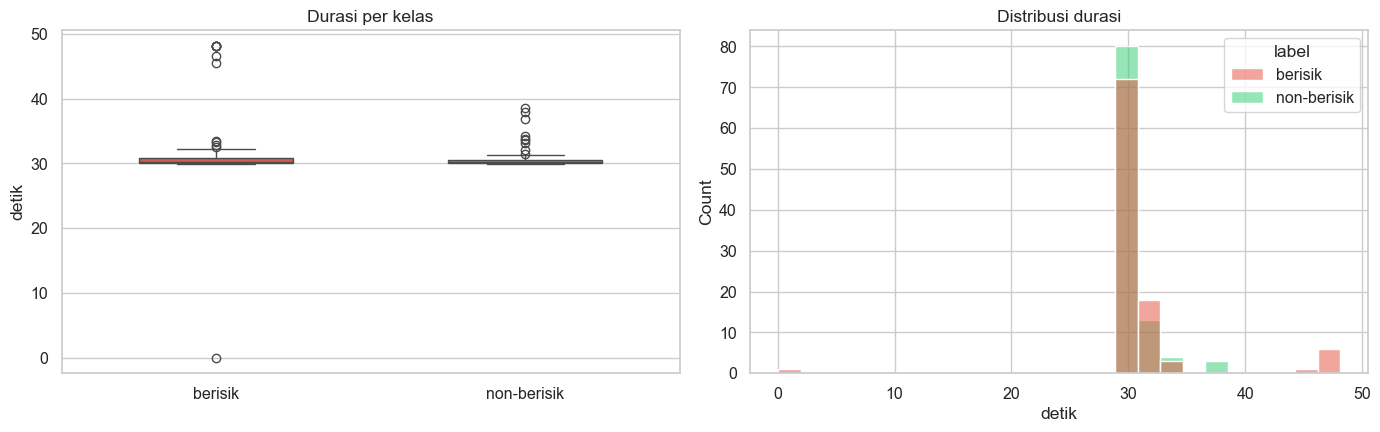

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df_files, x='label', y='duration_s', palette=PALETTE, width=0.5, ax=axes[0])
axes[0].set_title('Durasi per kelas'); axes[0].set_xlabel(''); axes[0].set_ylabel('detik')
sns.histplot(data=df_files, x='duration_s', hue='label', palette=PALETTE, bins=25, ax=axes[1])
axes[1].set_title('Distribusi durasi'); axes[1].set_xlabel('detik')
plt.tight_layout(); plt.show()

### Penjelasan Visualisasi Sinyal
Cell ini menampilkan waveform dan mel-spectrogram dari contoh audio. Waveform memperlihatkan perubahan amplitudo terhadap waktu, sedangkan mel-spectrogram memperlihatkan distribusi energi pada frekuensi yang dipetakan ke skala Mel. Perbandingan ini membantu melihat perbedaan noise floor antara audio berisik dan non-berisik.


### Visualisasi sinyal: mengapa berisik bisa dibedakan

Dua plot di bawah memperlihatkan waveform dan mel-spectrogram. Rekaman berisik punya **noise floor yang lebih tinggi dan merata di semua frekuensi**, sementara non-berisik punya ruang sunyi yang lebih dalam.

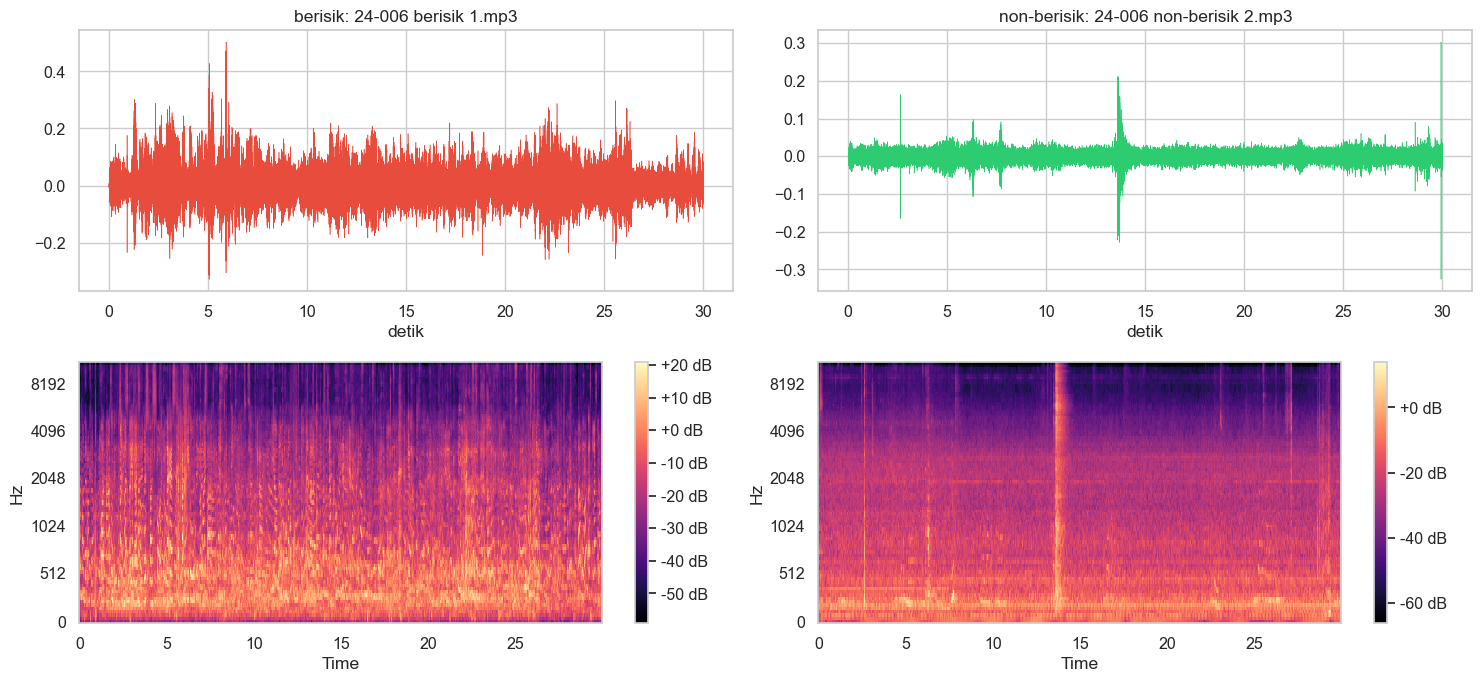

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for col, kelas in enumerate(KELAS):
    sample = df_files.query('label == @kelas').iloc[3]
    y = load_audio(sample.path)[:30 * SR]
    t = np.arange(len(y)) / SR
    axes[0, col].plot(t, y, lw=0.4, color=PALETTE[kelas])
    axes[0, col].set_title(f'{kelas}: {sample.file}'); axes[0, col].set_xlabel('detik')
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=96))
    img = librosa.display.specshow(mel, sr=SR, x_axis='time', y_axis='mel', ax=axes[1, col], cmap='magma')
    fig.colorbar(img, ax=axes[1, col], format='%+2.0f dB')
plt.tight_layout(); plt.show()

### Penjelasan Visualisasi Durasi dan Kelas
Cell ini membuat visualisasi eksplorasi tambahan untuk membandingkan distribusi durasi, jumlah data, atau karakteristik audio antar kelas. Visualisasi digunakan untuk menemukan ketidakseimbangan, pencilan durasi, dan pola awal sebelum fitur diekstraksi.


## Data Sampel (Tanpa Cleaning)

Sesuai instruksi, tahap pembersihan/pembuangan data dihapus agar seluruh sampel (genap 201 file: 101 berisik, 100 non-berisik) tetap digunakan secara utuh tanpa ada sampel yang dibuang.


In [6]:
df_files['md5'] = df_files.path.map(lambda p: hashlib.md5(p.read_bytes()).hexdigest())

dup_md5 = df_files.groupby('md5').file.apply(list)
dup_md5 = dup_md5[dup_md5.str.len() > 1]
print(f'Kelompok duplikat byte-identik: {len(dup_md5)}')
for files in dup_md5:
    labels = df_files.set_index('file').loc[files, 'label'].unique()
    flag = '  <-- KONFLIK LABEL' if len(labels) > 1 else ''
    print('  ', ' == '.join(files), flag)

Kelompok duplikat byte-identik: 15
   24-031 non-berisik 3.mp3 == 24-071 non berisik 1.mp3 
   24-157 Berisik 1.mp3 == 24-157 Berisik 2.mp3 == 24-157 Berisik 3.mp3 
   24-071 berisik 2.mp3 == 24-098 berisik 2.mp3 
   24-123 berisik 1.mp3 == 24-201 berisik 2.mp3 
   24-003 berisik (2).mp3 == 24-079 berisik 2.mp3 
   24-078_NonBerisik 2.mp3 == 24-078_NonBerisik 3.mp3 
   24-003 sunyi 3.mp3 == 24-079  non-berisik 1.mp3 
   24-003 berisik (3).mp3 == 24-079 berisik 1.mp3 == 24-123 berisik 3.mp3 
   24-031 non-berisik 2.mp3 == 24-071 non berisik 2.mp3 == 24-115_sampel non berisik 2.mp3 
   24-196 non berisik 1.mp3 == 24-196 non berisik 2.mp3 == 24-196 non berisik 3.mp3 
   24-031 non-berisik 1.mp3 == 24-071 non berisik 3.mp3 
   24-071 berisik 3.mp3 == 24-098 berisik 3.mp3 
   24-115 sampel berisik 3.mp3 == 24-190 berisik 3.mp3 
   24-003 sunyi 2.mp3 == 24-053 non-berisik 1.mp3 
   24-003 berisik (1).mp3 == 24-053 berisik 3.mp3 


### Penjelasan Audit Duplikasi
Cell ini menghitung checksum MD5 dari setiap file. File dengan checksum sama memiliki isi byte yang identik. Kelompok duplikat dan konflik label dicetak agar potensi data leakage atau pelabelan yang tidak konsisten dapat diketahui sebelum modeling.


In [7]:
# Deteksi konflik label juga pada file yang tidak byte-identik tapi hampir sama
probe = []
for row in df_files.itertuples():
    try:
        y = load_audio(row.path)[:30 * SR]
    except Exception:
        continue
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=32))
    probe.append({'file': row.file, 'label': row.label, 'hash': row.md5, **{f'm{i}': v for i, v in enumerate(mel.mean(1))}})
probe = pd.DataFrame(probe)
pcol = [c for c in probe.columns if c.startswith('m')]
Z = StandardScaler().fit_transform(probe[pcol])
D = np.linalg.norm(Z[:, None] - Z[None], axis=2)
np.fill_diagonal(D, np.inf)
is_b = (probe.label == 'berisik').values
near = D[is_b][:, ~is_b]
pairs = [(probe.file[is_b].iloc[i], probe.file[~is_b].iloc[j], near[i, j])
         for i, j in np.argwhere(near < 0.6)]
print('Pasangan hampir-identik lintas label (jarak < 0.6):')
for a, b, d in sorted(pairs, key=lambda x: x[2]):
    print(f'  {a:35s} <-> {b:35s} d={d:.3f}')

Pasangan hampir-identik lintas label (jarak < 0.6):
  24-168_Berisik1.mp3                 <-> 24-168_Non-Berisik2.mp3             d=0.580


### Penjelasan Pemeriksaan Kemiripan Lintas Label
Cell ini membandingkan representasi mel dari file berlabel berbeda. Jarak yang sangat kecil menunjukkan audio yang hampir identik meskipun labelnya berbeda. Pemeriksaan ini membantu mengidentifikasi konflik label yang tidak selalu terlihat dari checksum karena file dapat tersimpan dengan encoding atau metadata berbeda.


In [8]:
# Pembersihan data dilewati/dihapus agar seluruh 201 sampel tetap digunakan tanpa ada yang dibuang
df_clean = df_files.copy().sort_values('file').reset_index(drop=True)

print(f'Total file yang digunakan: {len(df_clean)} file (tidak ada yang dibuang)')
print(df_clean.label.value_counts().to_string())


Total file yang digunakan: 201 file (tidak ada yang dibuang)
label
berisik        101
non-berisik    100


### Penjelasan Penetapan Data Modeling
Cell ini membentuk `df_clean` dari inventaris data untuk dipakai pada tahap berikutnya. Pada konfigurasi notebook ini, proses cleaning tidak membuang sampel secara manual. Jumlah file dan distribusi label yang dicetak menjadi acuan untuk memastikan data yang masuk ke ekstraksi fitur sesuai dengan keputusan analisis.


## Ekstraksi Fitur

Fitur dirancang untuk menangkap **energi pada bagian sunyi** (noise floor), karena di situlah perbedaan utama kedua kelas:

| Kelompok | Fitur |
|---|---|
| Energi | RMS dalam dB: persentil 5/10/25/50/75/90/95, dynamic range, SNR estimasi |
| Noise floor | statistik spektral + MFCC pada 20% frame berenergi terendah |
| Spektral | flatness, centroid, bandwidth, rolloff, zero-crossing rate, spectral contrast |
| Timbre | MFCC 1–20 (mean/std/quiet-frame), 8 band noise-floor mel |

## Daftar Fitur yang Digunakan

Setiap file audio diubah menjadi fitur-fitur berikut:

| Kelompok | Fitur | Ringkasan yang disimpan | Jumlah fitur |
|---|---|---|---:|
| Energi | RMS dalam dB | Persentil P5, P10, P25, P50, P75, P90, P95; standar deviasi | 8 |
| Energi | Dynamic range dan estimasi SNR | Selisih P95-P5 dan P95-P10 | 2 |
| Spektral | Flatness, centroid, ZCR, bandwidth, rolloff | Mean, standar deviasi, dan mean quiet-frame untuk masing-masing | 15 |
| Timbre | MFCC 1 sampai 20 | Mean, standar deviasi, dan mean quiet-frame setiap koefisien | 60 |
| Noise-floor | 8 band Mel | Rata-rata energi pada quiet-frame untuk setiap band | 8 |
| Spektral | Spectral contrast | Rata-rata setiap sub-band | 7 |
| **Total** | | | **100 fitur** |

Jumlah di atas adalah jumlah yang diharapkan dari konfigurasi ekstraksi saat ini. Jadi, **jumlah fitur yang digunakan adalah 100 fitur**. Cell Python tepat setelah proses ekstraksi fitur (`feature-summary-code`), sebelum bagian **Analisis Fitur**, menampilkan jumlah tersebut secara otomatis dari `FEATURES`, seluruh nama fitur, dan pengelompokan fitur agar perubahan konfigurasi dapat terdeteksi.


## Rumus dan Perhitungan Manual Ekstraksi Fitur

Fitur audio digunakan untuk mengubah sinyal suara menjadi angka yang dapat dipelajari oleh model. Pada proyek ini, fitur dipilih untuk menangkap **energi**, **distribusi frekuensi**, **karakteristik noise**, dan **tekstur suara**. Contoh berikut menggunakan angka kecil agar setiap langkah perhitungan dapat diikuti. Angka contoh tidak menggantikan perhitungan pada dataset; implementasi sebenarnya menghitung fitur pada seluruh frame audio menggunakan `librosa`.

### Pembagian Sinyal Menjadi Frame

Audio dibagi menjadi beberapa frame pendek agar karakteristik suara dapat dianalisis dari waktu ke waktu. Misalkan satu frame memiliki 8 sampel:

$$
x = [0{,}20,\;-0{,}10,\;0{,}30,\;-0{,}40,\;0{,}10,\;0{,}00,\;-0{,}20,\;0{,}10]
$$

Dengan $N=8$, setiap fitur dihitung dari nilai-nilai pada frame tersebut. Setelah semua frame selesai dihitung, notebook menyimpan nilai **rata-rata**, **standar deviasi**, dan nilai pada *quiet-frame* jika fitur tersebut berbasis frame.

### RMS (Root Mean Square)

RMS mengukur energi atau amplitudo rata-rata audio. Rekaman berisik cenderung memiliki RMS yang lebih tinggi, terutama pada bagian yang seharusnya sunyi.

$$
\operatorname{RMS} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}x_i^2}
$$

Untuk 8 sampel di atas:

$$
\begin{aligned}
\operatorname{RMS}
&= \sqrt{\frac{0{,}20^2+(-0{,}10)^2+0{,}30^2+(-0{,}40)^2+0{,}10^2+0^2+(-0{,}20)^2+0{,}10^2}{8}}\\
&= \sqrt{\frac{0{,}04+0{,}01+0{,}09+0{,}16+0{,}01+0+0{,}04+0{,}01}{8}}\\
&= \sqrt{\frac{0{,}36}{8}} = \sqrt{0{,}045} \approx 0{,}212
\end{aligned}
$$

### RMS dalam Desibel (dB)

Nilai RMS diubah ke skala desibel agar rentang energi lebih mudah dibandingkan. Dengan referensi amplitudo $A_{\mathrm{ref}}=1$:

$$
L_{\mathrm{dB}} = 20\log_{10}\left(\frac{\operatorname{RMS}}{A_{\mathrm{ref}}}\right)
$$

Substitusi nilai RMS hasil contoh:

$$
\begin{aligned}
L_{\mathrm{dB}}
&=20\log_{10}\left(\frac{0{,}212}{1}\right)\\
&\approx 20(-0{,}674)\\
&\approx -13{,}48\;\mathrm{dB}
\end{aligned}
$$

Pada kode, ditambahkan bilangan kecil $\varepsilon=10^{-10}$ sebelum logaritma untuk mencegah $\log_{10}(0)$ ketika sebuah frame benar-benar hening.

### Persentil RMS-dB

Persentil menunjukkan posisi suatu nilai dalam distribusi energi seluruh frame. Notebook menghitung persentil ke-5, 10, 25, 50, 75, 90, dan 95.

Misalkan RMS-dB dari 10 frame yang sudah diurutkan adalah:

$$
[-40,\;-35,\;-30,\;-25,\;-20,\;-18,\;-15,\;-12,\;-10,\;-5]\;\mathrm{dB}
$$

Untuk ilustrasi metode *nearest-rank*, persentil ke-20 berada di sekitar sampel ke-2, yaitu $P_{20}\approx-35\;\mathrm{dB}$, sedangkan persentil ke-80 berada di sekitar sampel ke-8, yaitu $P_{80}\approx-12\;\mathrm{dB}$. Pada implementasi, `numpy.percentile` menggunakan interpolasi sesuai metode defaultnya, sehingga hasil dapat berupa angka desimal.

### Dynamic Range

Dynamic range menunjukkan jarak antara energi tinggi dan energi rendah pada audio. Nilai ini membantu membedakan audio yang memiliki perubahan energi besar dari audio yang energinya relatif rata.

$$
D = P_{95} - P_{5}
$$

Jika $P_{95}=-5\;\mathrm{dB}$ dan $P_{5}=-40\;\mathrm{dB}$:

$$
D=(-5)-(-40)=35\;\mathrm{dB}
$$

### Estimasi SNR

SNR (*Signal-to-Noise Ratio*) secara umum membandingkan kekuatan sinyal dengan noise. Pada notebook digunakan estimasi sederhana berbasis persentil energi: energi tinggi diwakili $P_{95}$ dan energi rendah diwakili $P_{10}$.

$$
\operatorname{SNR}_{\mathrm{est}} = P_{95} - P_{10}
$$

Dengan $P_{95}=-5\;\mathrm{dB}$ dan $P_{10}=-35\;\mathrm{dB}$:

$$
\operatorname{SNR}_{\mathrm{est}}=(-5)-(-35)=30\;\mathrm{dB}
$$

Nilai ini merupakan indikator relatif untuk klasifikasi, bukan pengukuran SNR laboratorium dengan sinyal bersih yang diketahui.

### Quiet-frame dan Noise Floor

*Quiet-frame* adalah 20% frame dengan RMS-dB terendah. Jika terdapat 10 frame, jumlah quiet-frame adalah:

$$
K=\lceil 0{,}20\times10\rceil=2\;\mathrm{frame}
$$

Dari daftar energi di atas, dua frame paling sunyi adalah $-40$ dan $-35\;\mathrm{dB}$. Rata-rata energi quiet-frame adalah:

$$
\overline{L}_{\mathrm{quiet}}=\frac{-40+(-35)}{2}=-37{,}5\;\mathrm{dB}
$$

Bagian ini digunakan sebagai pendekatan *noise floor*: apabila audio berisik, energi latar pada frame tersunyi tetap relatif tinggi.

### ZCR (Zero-Crossing Rate)

ZCR menghitung seberapa sering sinyal berpindah tanda dari positif ke negatif atau sebaliknya. Noise dan komponen frekuensi tinggi biasanya menghasilkan ZCR yang lebih tinggi.

$$
\operatorname{ZCR}=\frac{1}{2(N-1)}\sum_{n=1}^{N-1}\left|\operatorname{sgn}(x_n)-\operatorname{sgn}(x_{n-1})\right|
$$

Untuk contoh, tanda sampel dapat ditulis sebagai:

$$
[+,-,+,-,+,0,-,+]
$$

Jika nilai nol dianggap tidak menambah perpindahan tanda, terdapat 6 perpindahan dari 7 pasangan sampel. Dengan bentuk hitung sederhana:

$$
\operatorname{ZCR}\approx\frac{6}{7}=0{,}857
$$

Implementasi `librosa.feature.zero_crossing_rate` menghitungnya secara konsisten pada setiap frame. Notebook kemudian menyimpan mean, standar deviasi, dan mean ZCR pada quiet-frame.

### Spektral Centroid

Spectral centroid menunjukkan pusat massa distribusi frekuensi dan sering dipersepsikan sebagai tingkat ?kecerahan? suara. Centroid tinggi berarti lebih banyak energi berada pada frekuensi tinggi.

Misalkan terdapat 4 bin frekuensi:

$$
f=[100,\;200,\;300,\;400]\;\mathrm{Hz}
$$

dan daya tiap bin:

$$
p=[1,\;4,\;1,\;0]
$$

Rumus centroid:

$$
C=\frac{\sum_k f_kp_k}{\sum_kp_k}
$$

Perhitungannya:

$$
C=\frac{100(1)+200(4)+300(1)+400(0)}{1+4+1+0}
=\frac{1300}{6}\approx216{,}67\;\mathrm{Hz}
$$

### Spectral Bandwidth

Bandwidth mengukur penyebaran energi frekuensi di sekitar centroid. Jika energi tersebar luas, bandwidth lebih besar.

$$
B=\sqrt{\frac{\sum_k p_k(f_k-C)^2}{\sum_kp_k}}
$$

Dengan $C=216{,}67\;\mathrm{Hz}$:

$$
\begin{aligned}
B&=\sqrt{\frac{1(100-216{,}67)^2+4(200-216{,}67)^2+1(300-216{,}67)^2+0(400-216{,}67)^2}{6}}\\
&\approx\sqrt{\frac{1388{,}89+18{,}52+1152{,}78}{6}}\approx37{,}27\;\mathrm{Hz}
\end{aligned}
$$

### Spectral Rolloff

Rolloff adalah frekuensi ketika akumulasi daya mencapai proporsi tertentu, umumnya 85%. Total daya pada contoh adalah:

$$
P_{\mathrm{total}}=1+4+1+0=6
$$

Ambang 85%:

$$
0{,}85\times6=5{,}1
$$

Akumulasi daya dari frekuensi rendah adalah $[1,5,6,6]$. Nilai pertama yang melewati 5,1 berada pada bin 300 Hz, sehingga:

$$
\operatorname{rolloff}_{85\%}=300\;\mathrm{Hz}
$$

### Spectral Flatness

Flatness membandingkan rata-rata geometrik dengan rata-rata aritmetika daya. Nilai mendekati 1 menunjukkan spektrum lebih merata seperti noise, sedangkan nilai kecil menunjukkan adanya puncak frekuensi dominan.

$$
F=\frac{\left(\prod_{k=1}^{K}p_k\right)^{1/K}}{\frac{1}{K}\sum_{k=1}^{K}p_k}
$$

Untuk contoh daya $p=[1,2,4,2]$:

$$
\begin{aligned}
\text{rata-rata geometrik}&=(1\times2\times4\times2)^{1/4}=2\\
\text{rata-rata aritmetika}&=\frac{1+2+4+2}{4}=2{,}25\\
F&=\frac{2}{2{,}25}\approx0{,}889
\end{aligned}
$$

Pada implementasi, nilai kecil ditambahkan jika diperlukan agar tidak terjadi logaritma atau perkalian dengan nol. Notebook menyimpan mean, standar deviasi, dan nilai quiet-frame untuk flatness.

### MFCC: Filterbank Mel, Log, dan DCT

MFCC (*Mel-Frequency Cepstral Coefficients*) merangkum bentuk spektrum menggunakan skala Mel yang lebih dekat dengan persepsi pendengaran manusia. Tahap utamanya adalah: menghitung energi filter Mel, mengambil log, lalu menerapkan DCT.

Sebagai contoh, gunakan 4 bin energi dan 3 filter Mel:

$$
E=[1,2,4,2]
$$

$$
\begin{aligned}
H_1&=[1,0{,}5,0,0]\\
H_2&=[0,0{,}5,1,0{,}5]\\
H_3&=[0,0,0{,}5,1]
\end{aligned}
$$

Energi tiap filter dihitung dengan:

$$
M_j=\sum_{k=1}^{K}E_kH_{j,k}
$$

Sehingga:

$$
\begin{aligned}
M_1&=1(1)+2(0{,}5)+4(0)+2(0)=2\\
M_2&=1(0)+2(0{,}5)+4(1)+2(0{,}5)=6\\
M_3&=1(0)+2(0)+4(0{,}5)+2(1)=4
\end{aligned}
$$

Selanjutnya ambil log natural dari energi filter:

$$
L_j=\ln(M_j)
$$

$$
L=[\ln(2),\ln(6),\ln(4)]\approx[0{,}693,1{,}792,1{,}386]
$$

DCT-II untuk 3 filter dapat dituliskan sebagai:

$$
C_n=\sum_{j=1}^{3}L_j\cos\left[\frac{\pi n}{3}\left(j-\frac{1}{2}\right)\right]
$$

Contoh koefisiennya:

$$
\begin{aligned}
C_0&=0{,}693+1{,}792+1{,}386=3{,}871\\
C_1&=0{,}693\cos\left(\frac{\pi}{6}\right)+1{,}792\cos\left(\frac{3\pi}{6}\right)+1{,}386\cos\left(\frac{5\pi}{6}\right)\\
&\approx0{,}600+0-1{,}200=-0{,}600
\end{aligned}
$$

Pada notebook digunakan 40 mel band dan 20 koefisien MFCC. Untuk setiap koefisien, disimpan mean seluruh frame, standar deviasi, dan mean pada quiet-frame.

### Noise-floor Mel Band

Energi Mel pada quiet-frame dirata-ratakan untuk melihat frekuensi yang tetap memiliki energi ketika sinyal utama sedang rendah. Misalkan satu kelompok band memiliki nilai:

$$
[-30,-28]\;\mathrm{dB}
$$

Maka nilai noise band-nya adalah:

$$
\operatorname{noise\_band}=\frac{-30+(-28)}{2}=-29\;\mathrm{dB}
$$

Dalam implementasi, 40 mel band dibagi menjadi 8 kelompok dan rata-rata setiap kelompok disimpan sebagai fitur `noise_band1` sampai `noise_band8`.

### Spectral Contrast

Spectral contrast membandingkan energi puncak dan lembah pada sub-band frekuensi. Kontras yang besar menunjukkan perbedaan jelas antara puncak dan lembah spektrum.

Misalkan rata-rata energi puncak adalah 11 dB dan rata-rata energi lembah adalah 2 dB:

$$
\operatorname{contrast}=\overline{P}_{\mathrm{peak}}-\overline{P}_{\mathrm{valley}}=11-2=9\;\mathrm{dB}
$$

Notebook menghitung spectral contrast pada beberapa sub-band dan menyimpan rata-rata tiap sub-band sebagai fitur `contrast1`, `contrast2`, dan seterusnya.

### Ringkasan Fitur yang Masuk ke Model

- **Energi:** RMS-dB pada persentil 5, 10, 25, 50, 75, 90, dan 95, dynamic range, estimasi SNR, serta standar deviasi RMS-dB.
- **Fitur spektral:** mean, standar deviasi, dan quiet-frame untuk flatness, centroid, ZCR, bandwidth, dan rolloff.
- **Timbre:** mean, standar deviasi, dan quiet-frame untuk 20 koefisien MFCC.
- **Noise floor:** 8 fitur noise-band Mel yang dihitung dari 20% frame paling sunyi.
- **Tekstur spektrum:** rata-rata spectral contrast pada setiap sub-band.

Semua ringkasan fitur tersebut digabung menjadi satu baris untuk setiap file audio, kemudian digunakan sebagai input pada tahap seleksi fitur dan klasifikasi.


In [9]:
def ekstrak_fitur(y, sr=SR):
    f = {}
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512))

    # --- energi ---
    rms = librosa.feature.rms(S=S)[0]
    rms_db = librosa.amplitude_to_db(rms + 1e-10, ref=1.0)
    pct = np.percentile(rms_db, [5, 10, 25, 50, 75, 90, 95])
    for q, v in zip([5, 10, 25, 50, 75, 90, 95], pct):
        f[f'rmsdb_p{q}'] = v
    f['dyn_range'] = pct[-1] - pct[0]
    f['snr_est'] = pct[-1] - pct[1]
    f['rmsdb_std'] = rms_db.std()

    # --- frame tersunyi = noise floor ---
    quiet = rms_db <= np.percentile(rms_db, 20)
    flat = librosa.feature.spectral_flatness(S=S)[0]
    cent = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    zcr = librosa.feature.zero_crossing_rate(y, hop_length=512)[0][:S.shape[1]]
    for nama, v in {
        'flat': flat,
        'cent': cent,
        'zcr': zcr,
        'bw': librosa.feature.spectral_bandwidth(S=S, sr=sr)[0],
        'roll': librosa.feature.spectral_rolloff(S=S, sr=sr)[0],
    }.items():
        v = v[:len(quiet)]
        f[f'{nama}_mean'] = v.mean()
        f[f'{nama}_std'] = v.std()
        f[f'{nama}_quiet'] = v[quiet[:len(v)]].mean()

    # --- MFCC ---
    mel = librosa.power_to_db(librosa.feature.melspectrogram(S=S ** 2, sr=sr, n_mels=40))
    mfcc = librosa.feature.mfcc(S=mel, n_mfcc=20)
    for i in range(20):
        f[f'mfcc{i + 1}_mean'] = mfcc[i].mean()
        f[f'mfcc{i + 1}_std'] = mfcc[i].std()
        f[f'mfcc{i + 1}_quiet'] = mfcc[i][quiet].mean()

    # --- noise floor per band mel ---
    mq = mel[:, quiet].mean(axis=1)
    for i, band in enumerate(np.array_split(mq, 8)):
        f[f'noise_band{i + 1}'] = band.mean()

    # --- spectral contrast ---
    con = librosa.feature.spectral_contrast(S=S, sr=sr)
    for i in range(con.shape[0]):
        f[f'contrast{i + 1}'] = con[i].mean()
    return f

print('Fitur per file:', len(ekstrak_fitur(load_audio(df_clean.path.iloc[0]))))

Fitur per file: 100


### Penjelasan Fungsi Ekstraksi Fitur
Cell ini mendefinisikan `ekstrak_fitur`, yaitu fungsi utama yang mengubah satu audio menjadi 100 fitur numerik. Fitur mencakup RMS-dB dan statistik energinya, fitur spektral, MFCC, noise-floor Mel, serta spectral contrast. Fungsi juga menghitung statistik pada 20% frame dengan energi terendah untuk menangkap karakteristik suara latar. Baris terakhir menguji fungsi pada satu file dan mencetak jumlah fitur.


In [10]:
records, skip = [], []
for i, row in enumerate(df_clean.itertuples(), 1):
    try:
        # 2 kolom awal: nama file audio dan label nya
        rec = {'file': row.file, 'label': row.label}
        rec.update(ekstrak_fitur(load_audio(row.path)))
        records.append(rec)
    except Exception as exc:
        skip.append(row.file)
        print(f'[SKIP] {row.file} -> {exc}')
    if i % 40 == 0:
        print(f'  {i}/{len(df_clean)} selesai')

df = pd.DataFrame(records)
# Pastikan posisi 2 kolom awal adalah 'file' dan 'label'
kolom_awal = ['file', 'label']
kolom_fitur = [c for c in df.columns if c not in ('file', 'label', 'md5')]
df = df[kolom_awal + kolom_fitur]
FEATURES = kolom_fitur
print(f'\nShape: {df.shape} | jumlah fitur: {len(FEATURES)} | dilewati: {len(skip)}')
df.to_csv('../output_fitur_berisik.csv', index=False)
df.head(3)


  40/201 selesai
  80/201 selesai
  120/201 selesai
  160/201 selesai
  200/201 selesai

Shape: (201, 102) | jumlah fitur: 100 | dilewati: 0


,file,label,rmsdb_p5,rmsdb_p10,rmsdb_p25,rmsdb_p50,rmsdb_p75,rmsdb_p90,rmsdb_p95,dyn_range,...,noise_band6,noise_band7,noise_band8,contrast1,contrast2,contrast3,contrast4,contrast5,contrast6,contrast7
0,24-003 berisik (1).mp3,berisik,-42.240409,-40.725087,-36.848579,-33.108852,-29.683816,-26.803222,-25.322854,16.917555,...,-33.743481,-31.974997,-45.347210,23.883399,14.407455,18.202891,18.364323,19.628800,21.215021,64.402323
1,24-003 berisik (2).mp3,berisik,-50.211131,-43.896641,-34.648829,-27.809125,-23.385540,-20.620440,-19.390105,30.821026,...,-27.648159,-38.599171,-51.308159,21.923970,16.463773,21.069099,20.371821,20.905576,27.293818,54.476193
2,24-003 berisik (3).mp3,berisik,-52.017667,-49.129747,-42.157970,-34.001625,-25.962273,-22.685577,-21.501662,30.516004,...,-26.663376,-37.992584,-56.200298,21.017729,16.644519,19.074469,17.963586,19.291831,28.766078,56.716962


### Penjelasan Ekstraksi Fitur Seluruh Dataset
Cell ini menjalankan `ekstrak_fitur` untuk setiap file dalam `df_clean`. Hasilnya digabungkan dengan nama file dan label menjadi DataFrame `df`, lalu daftar nama fitur disimpan dalam `FEATURES`. Dataset fitur juga diekspor ke CSV sehingga dapat diperiksa atau digunakan kembali tanpa mengulang ekstraksi audio.


In [11]:
# Ringkasan fitur yang benar-benar dihasilkan dan digunakan model
def kelompok_fitur(nama):
    if nama.startswith('rmsdb_') or nama in {'dyn_range', 'snr_est'}:
        return 'Energi'
    if nama.startswith(('flat_', 'cent_', 'zcr_', 'bw_', 'roll_')):
        return 'Fitur spektral'
    if nama.startswith('mfcc'):
        return 'MFCC / timbre'
    if nama.startswith('noise_band'):
        return 'Noise-floor Mel'
    if nama.startswith('contrast'):
        return 'Spectral contrast'
    return 'Lainnya'

grouped_features = {}
for feature in FEATURES:
    grouped_features.setdefault(kelompok_fitur(feature), []).append(feature)

print(f'Jumlah file: {len(df)}')
print(f'Jumlah fitur yang digunakan model: {len(FEATURES)} fitur')
print(f'Jumlah kolom data (file + label + fitur): {df.shape[1]}\n')
for group, names in grouped_features.items():
    print(f'{group}: {len(names)} fitur')
    print('  ' + ', '.join(names))

assert len(FEATURES) == len(set(FEATURES)), 'Nama fitur harus unik.'


Jumlah file: 201
Jumlah fitur yang digunakan model: 100 fitur
Jumlah kolom data (file + label + fitur): 102

Energi: 10 fitur
  rmsdb_p5, rmsdb_p10, rmsdb_p25, rmsdb_p50, rmsdb_p75, rmsdb_p90, rmsdb_p95, dyn_range, snr_est, rmsdb_std
Fitur spektral: 15 fitur
  flat_mean, flat_std, flat_quiet, cent_mean, cent_std, cent_quiet, zcr_mean, zcr_std, zcr_quiet, bw_mean, bw_std, bw_quiet, roll_mean, roll_std, roll_quiet
MFCC / timbre: 60 fitur
  mfcc1_mean, mfcc1_std, mfcc1_quiet, mfcc2_mean, mfcc2_std, mfcc2_quiet, mfcc3_mean, mfcc3_std, mfcc3_quiet, mfcc4_mean, mfcc4_std, mfcc4_quiet, mfcc5_mean, mfcc5_std, mfcc5_quiet, mfcc6_mean, mfcc6_std, mfcc6_quiet, mfcc7_mean, mfcc7_std, mfcc7_quiet, mfcc8_mean, mfcc8_std, mfcc8_quiet, mfcc9_mean, mfcc9_std, mfcc9_quiet, mfcc10_mean, mfcc10_std, mfcc10_quiet, mfcc11_mean, mfcc11_std, mfcc11_quiet, mfcc12_mean, mfcc12_std, mfcc12_quiet, mfcc13_mean, mfcc13_std, mfcc13_quiet, mfcc14_mean, mfcc14_std, mfcc14_quiet, mfcc15_mean, mfcc15_std, mfcc15_quiet, 

### Penjelasan Ringkasan Fitur
Cell ini menampilkan jumlah file, jumlah fitur yang benar-benar digunakan, jumlah kolom DataFrame, serta nama fitur berdasarkan kelompoknya. Nilai jumlah fitur dihitung langsung dari `FEATURES`, sehingga output tetap akurat jika konfigurasi ekstraksi berubah. Assertion terakhir memastikan tidak ada nama fitur yang duplikat.


## Analisis Fitur

Fitur mana yang paling memisahkan dua kelas? Uji ANOVA F-score dipakai sebagai peringkat, sekaligus untuk feature selection.

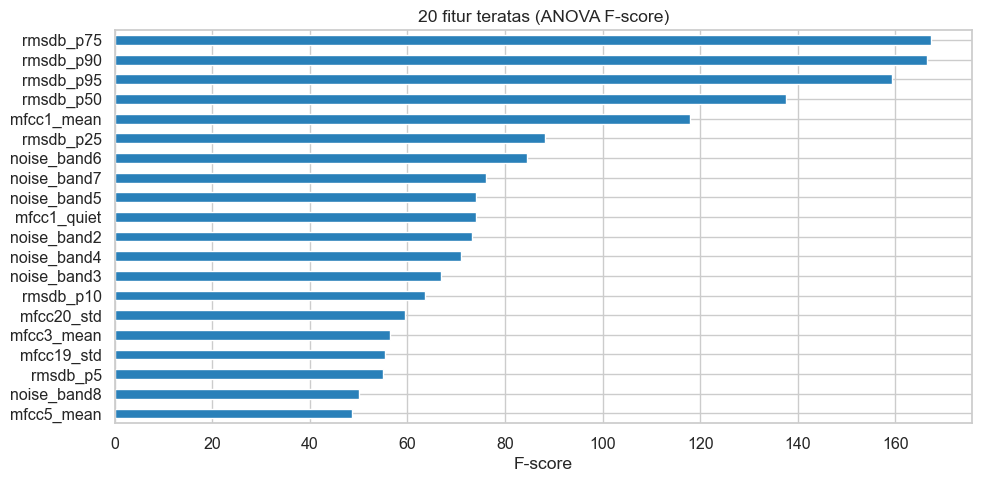

'rmsdb_p75      167.4\nrmsdb_p90      166.5\nrmsdb_p95      159.3\nrmsdb_p50      137.5\nmfcc1_mean     117.9\nrmsdb_p25       88.1\nnoise_band6     84.4\nnoise_band7     76.1\nnoise_band5     74.0\nmfcc1_quiet     74.0\nnoise_band2     73.2\nnoise_band4     71.0\nnoise_band3     66.8\nrmsdb_p10       63.7\nmfcc20_std      59.5'

In [12]:
X_all = df[FEATURES].values
y_all = (df.label == 'berisik').astype(int).values

fscore = SelectKBest(f_classif, k='all').fit(StandardScaler().fit_transform(X_all), y_all)
peringkat = pd.Series(fscore.scores_, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
peringkat.head(20)[::-1].plot.barh(ax=ax, color='#2980b9')
ax.set_title('20 fitur teratas (ANOVA F-score)'); ax.set_xlabel('F-score')
plt.tight_layout(); plt.show()
peringkat.head(15).round(1).to_string()

### Penjelasan Analisis Fitur
Cell ini memisahkan prediktor `X_all` dari target `y_all`, kemudian menghitung ANOVA F-score untuk mengurutkan fitur berdasarkan kemampuan membedakan kelas. Plot 20 fitur teratas membantu melihat fitur yang paling informatif sebelum model final melakukan seleksi fitur.


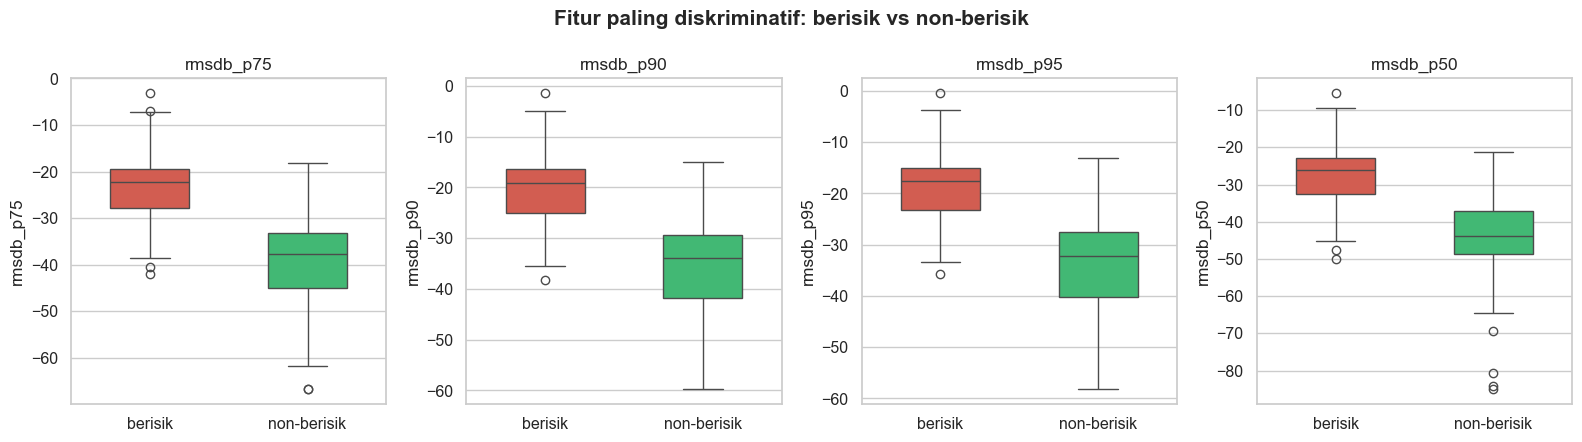

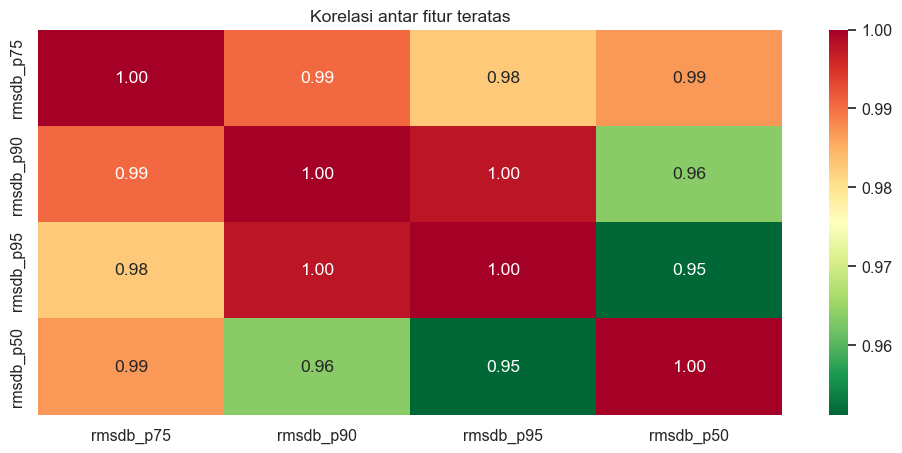

In [13]:
top4 = peringkat.head(4).index
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, top4):
    sns.boxplot(data=df, x='label', y=col, palette=PALETTE, width=0.5, ax=ax)
    ax.set_title(col); ax.set_xlabel('')
plt.suptitle('Fitur paling diskriminatif: berisik vs non-berisik', fontweight='bold')
plt.tight_layout(); plt.show()

corr = df[top4].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn_r'); plt.title('Korelasi antar fitur teratas'); plt.show()

### Penjelasan Korelasi dan Distribusi Fitur Teratas
Cell ini memilih empat fitur dengan F-score tertinggi, lalu menampilkan boxplot berdasarkan label dan heatmap korelasi Spearman. Boxplot memperlihatkan perbedaan distribusi antar kelas, sedangkan korelasi membantu mengetahui apakah fitur-fitur teratas membawa informasi yang mirip.


## Modeling

Tahap modeling membandingkan lima algoritma baseline menggunakan **stratified 5-fold cross-validation**. Stratifikasi menjaga proporsi kelas `berisik` dan `non-berisik` tetap serupa pada setiap fold.

Model baseline yang dibandingkan:

1. **SVM RBF**: mampu memodelkan batas keputusan non-linear pada fitur audio.
2. **Logistic Regression**: baseline linear yang mudah diinterpretasikan.
3. **Random Forest**: ensemble pohon keputusan dengan sampling fitur dan data.
4. **Extra Trees**: ensemble pohon dengan pemilihan split yang lebih acak.
5. **K-NN**: mengklasifikasikan sampel berdasarkan tetangga terdekat setelah standardisasi.

Model final menggunakan pipeline berikut:

```text
StandardScaler ? SelectKBest(f_classif) ? SVC(RBF, probability=True)
```

- `StandardScaler` menyamakan skala seluruh fitur.
- `SelectKBest` memilih fitur berdasarkan ANOVA F-score.
- `SVC(RBF)` mempelajari batas keputusan non-linear dan menghasilkan probabilitas prediksi.

Tuning dilakukan dengan `GridSearchCV` menggunakan `RepeatedStratifiedKFold(n_splits=5, n_repeats=2)`. Grid yang dicoba adalah:

- jumlah fitur terpilih `k`: `60`, `80`, atau `all`;
- parameter SVM `C`: `1`, `3`, `10`, atau `30`;
- parameter kernel `gamma`: `scale`, `0.01`, `0.03`, atau `0.05`.

Pemilihan parameter hanya menggunakan data train. Data test tidak digunakan selama tuning agar tetap menjadi evaluasi akhir yang tidak bias.


## Perbandingan Model Baseline

Semua model dievaluasi dengan **stratified 5-fold cross-validation** pada data yang sudah dibersihkan. SVM RBF dipakai sebagai kandidat utama karena cocok untuk data fitur berdimensi sedang dengan jumlah sampel kecil (±170).

### Ringkasan Hasil Baseline

Hasil stratified 5-fold cross-validation pada lima model baseline adalah sebagai berikut. Nilai akurasi ditulis sebagai rata-rata ± standar deviasi antar-fold.

| Model | Rata-rata Akurasi | Standar Deviasi |
|---|---:|---:|
| SVM (RBF) | 93,52% | 2,02% |
| Logistic Regression | 89,04% | 3,43% |
| Random Forest | 91,02% | 3,03% |
| Extra Trees | 93,02% | 1,90% |
| K-NN ($k=5$) | 87,56% | 2,24% |

SVM RBF memperoleh rata-rata akurasi tertinggi dan dipilih sebagai kandidat model final. Standar deviasi menunjukkan variasi performa antar-fold; semakin kecil nilainya, semakin stabil performa model pada pembagian data yang berbeda.


SVM (RBF)              akurasi CV = 0.9352 +/- 0.0202
Logistic Regression    akurasi CV = 0.8904 +/- 0.0343
Random Forest          akurasi CV = 0.9102 +/- 0.0303
Extra Trees            akurasi CV = 0.9302 +/- 0.0190
K-NN (k=5)             akurasi CV = 0.8756 +/- 0.0224


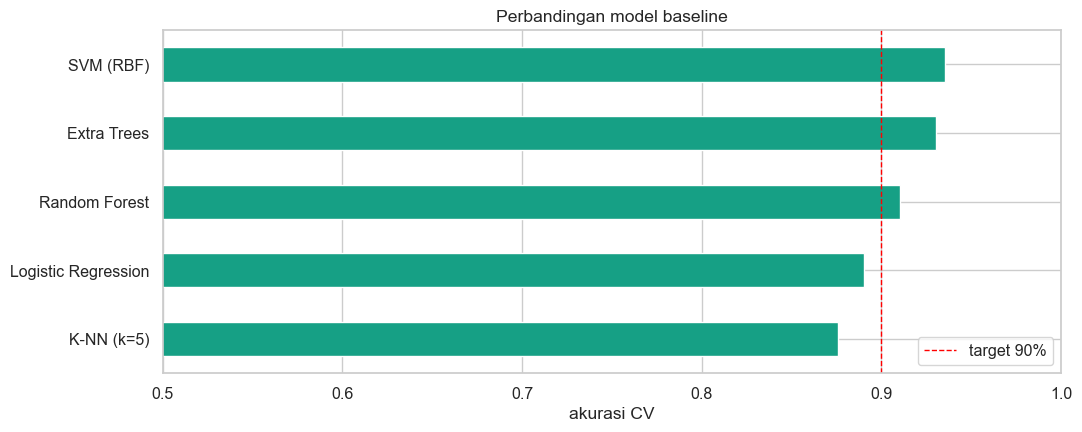

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_models = {
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(C=10, gamma=0.01)),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5)),
    'Random Forest': RandomForestClassifier(500, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(500, random_state=RANDOM_STATE, n_jobs=-1),
    'K-NN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5, weights='distance')),
}

hasil = {}
for nama, model in baseline_models.items():
    skor = cross_val_score(model, X_all, y_all, cv=cv, scoring='accuracy')
    hasil[nama] = skor
    print(f'{nama:22s} akurasi CV = {skor.mean():.4f} +/- {skor.std():.4f}')

df_hasil = pd.DataFrame(hasil)
fig, ax = plt.subplots(figsize=(11, 4.5))
df_hasil.mean().sort_values().plot.barh(ax=ax, color='#16a085')
ax.axvline(0.9, color='red', ls='--', lw=1, label='target 90%')
ax.set_xlim(0.5, 1.0); ax.set_xlabel('akurasi CV'); ax.legend()
ax.set_title('Perbandingan model baseline')
plt.tight_layout(); plt.show()

### Penjelasan Perbandingan Baseline
Cell ini membandingkan lima model baseline menggunakan stratified 5-fold cross-validation. Setiap model memperoleh rata-rata akurasi dan standar deviasi, sehingga performa serta kestabilannya dapat dibandingkan sebelum tuning. Hasil ini menjadi dasar pemilihan SVM RBF sebagai kandidat model final.


## Split Data

Data dibagi secara **stratified 80/20** menggunakan `random_state=42`:

```python
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=0.2,
    stratify=y_all,
    random_state=42,
)
```

Dengan total 201 file, pembagian yang digunakan adalah:

- **Data train: 160 file**
- **Data test/holdout: 41 file**

Stratifikasi mempertahankan perbandingan kelas pada train dan test. Data test hanya digunakan setelah proses tuning selesai.

Selain holdout test, evaluasi tambahan menggunakan **5?5-fold cross-validation**: lima pembagian 5-fold dengan lima nilai seed berbeda (`42`, `1`, `7`, `13`, dan `21`). Hasilnya digunakan untuk mengukur kestabilan performa model pada pembagian data yang berbeda.


## Tuning Hyperparameter (Protocol Ketat)

Tuning memakai **`RepeatedStratifiedKFold` (5 fold × 2 ulangan)** agar pemilihan hyperparameter tidak bergantung pada satu pembagian data. Data dipecah 80/20 lebih dulu; tuning **hanya** melihat bagian train, sehingga 20% data test tetap murni sebagai uji akhir.

### Arti Hyperparameter Model Final

Hasil `GridSearchCV` memilih kombinasi hyperparameter terbaik berdasarkan akurasi cross-validation pada data train. Parameter yang dicari memiliki arti berikut:

- **`selector__k`** menentukan jumlah fitur yang dipertahankan oleh `SelectKBest`. Nilai `60` dan `80` memilih sebagian fitur dengan ANOVA F-score tertinggi, sedangkan `all` mempertahankan seluruh 100 fitur.
- **`svm__C`** mengatur penalti kesalahan klasifikasi. Nilai `C` lebih besar memberi penalti lebih kuat terhadap kesalahan pada data train, tetapi dapat meningkatkan risiko overfitting.
- **`svm__gamma`** mengatur jangkauan pengaruh setiap titik data pada kernel RBF. Gamma besar menghasilkan batas keputusan yang lebih lokal, sedangkan gamma kecil menghasilkan batas yang lebih halus.

Pada eksekusi yang terdokumentasi, kombinasi terbaik adalah `k='all'`, `C=10`, dan `gamma=0.03`. Dengan demikian, pipeline tetap menggunakan `SelectKBest`, tetapi konfigurasi terbaik mempertahankan seluruh 100 fitur.


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
print(f'Train: {len(y_train)} | Test: {len(y_test)}')

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('svm', SVC(probability=True, random_state=RANDOM_STATE)),
])
param_grid = {
    'selector__k': [60, 80, 'all'],
    'svm__C': [1, 3, 10, 30],
    'svm__gamma': ['scale', 0.01, 0.03, 0.05],
}
grid = GridSearchCV(
    pipeline, param_grid,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0),
    scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)
BEST = grid.best_params_
print('Best params     :', BEST)
print(f'CV internal     : {grid.best_score_:.4f}')

Train: 160 | Test: 41
Best params     : {'selector__k': 60, 'svm__C': 3, 'svm__gamma': 0.05}
CV internal     : 0.9125


### Penjelasan Split dan Tuning
Cell ini membagi data secara stratified menjadi data train dan holdout test menggunakan rasio 80/20 serta `random_state=42`. Pipeline kemudian melakukan standardisasi, seleksi fitur, dan SVM RBF. `GridSearchCV` mencoba kombinasi `k`, `C`, dan `gamma` dengan RepeatedStratifiedKFold 5 fold ? 2 pengulangan hanya pada data train.


## Evaluasi Model

Performa model dinilai menggunakan beberapa sudut pandang:

- **Akurasi holdout:** proporsi prediksi benar pada 41 file test yang tidak digunakan saat training dan tuning.
- **Classification report:** menampilkan precision, recall, F1-score, dan support untuk kelas `non-berisik` serta `berisik`.
- **Confusion matrix:** menunjukkan jumlah true positive, true negative, false positive, dan false negative.
- **5?5-fold CV:** menghitung akurasi pada lima pengulangan 5-fold untuk melihat kestabilan model.
- **Voting segmen 5 detik:** setiap file dipotong menjadi segmen 5 detik, tiap segmen diprediksi, lalu probabilitas segmen dirata-ratakan kembali pada level file. Semua segmen dari file yang sama tetap berada pada group yang sama agar tidak terjadi data leakage.

Model file-level dipilih sebagai model final karena lebih sederhana dan pada eksperimen ini memberikan hasil yang lebih baik dibandingkan pendekatan voting segmen.


## Evaluasi Model File-Level

Model hasil tuning diuji pada data holdout, lalu diukur ulang dengan **5×5-fold cross-validation** (5 fold × 5 seed berbeda) pada seluruh data bersih untuk melihat kestabilan estimasi.

### Cara Membaca Confusion Matrix

Confusion matrix menggunakan baris sebagai label aktual dan kolom sebagai label prediksi:

| | Prediksi non-berisik | Prediksi berisik |
|---|---:|---:|
| **Aktual non-berisik** | TN | FP |
| **Aktual berisik** | FN | TP |

- **TN (True Negative):** audio non-berisik yang berhasil dikenali sebagai non-berisik.
- **FP (False Positive):** audio non-berisik yang salah diberi label berisik.
- **FN (False Negative):** audio berisik yang salah diberi label non-berisik.
- **TP (True Positive):** audio berisik yang berhasil dikenali sebagai berisik.

Cell Python setelah evaluasi mencetak nilai TN, FP, FN, dan TP dari hasil aktual `y_test` dan prediksi `y_pred`. Dengan begitu, interpretasi di catatan selalu mengikuti hasil training terakhir.


In [16]:
model_file = grid.best_estimator_
y_pred = model_file.predict(X_test)
akurasi_test = accuracy_score(y_test, y_pred)
print(f'Akurasi holdout test = {akurasi_test:.4f} ({akurasi_test * 100:.2f}%)')
print()
print(classification_report(y_test, y_pred, target_names=['non-berisik', 'berisik'], digits=3))

Akurasi holdout test = 0.9268 (92.68%)

              precision    recall  f1-score   support

 non-berisik      0.870     1.000     0.930        20
     berisik      1.000     0.857     0.923        21

    accuracy                          0.927        41
   macro avg      0.935     0.929     0.927        41
weighted avg      0.936     0.927     0.927        41



### Penjelasan Evaluasi Holdout
Cell ini mengambil estimator terbaik dari hasil tuning, memprediksi data test yang belum digunakan selama training, lalu menghitung akurasi dan classification report. Precision, recall, F1-score, dan support membantu melihat performa secara terpisah untuk kelas non-berisik dan berisik.


In [ ]:
# Ringkasan numerik confusion matrix agar hasil mudah dicatat tanpa hanya melihat plot.
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix (baris = aktual, kolom = prediksi):')
print(pd.DataFrame(cm,
                   index=['Aktual non-berisik', 'Aktual berisik'],
                   columns=['Prediksi non-berisik', 'Prediksi berisik']))
print(f'\n
TN (non-berisik benar) : {tn}')
print(f'FP (non-berisik jadi berisik) : {fp}')
print(f'FN (berisik jadi non-berisik) : {fn}')
print(f'TP (berisik benar) : {tp}')
print(f'Prediksi benar       : {tn + tp} dari {len(y_test)}')


### Penjelasan Ringkasan Confusion Matrix
Cell ini mengubah hasil prediksi holdout menjadi confusion matrix numerik. TN menunjukkan non-berisik yang benar, FP non-berisik yang salah menjadi berisik, FN berisik yang salah menjadi non-berisik, dan TP berisik yang benar. Jumlah prediksi benar juga dicetak agar hasil mudah ditulis dalam catatan.


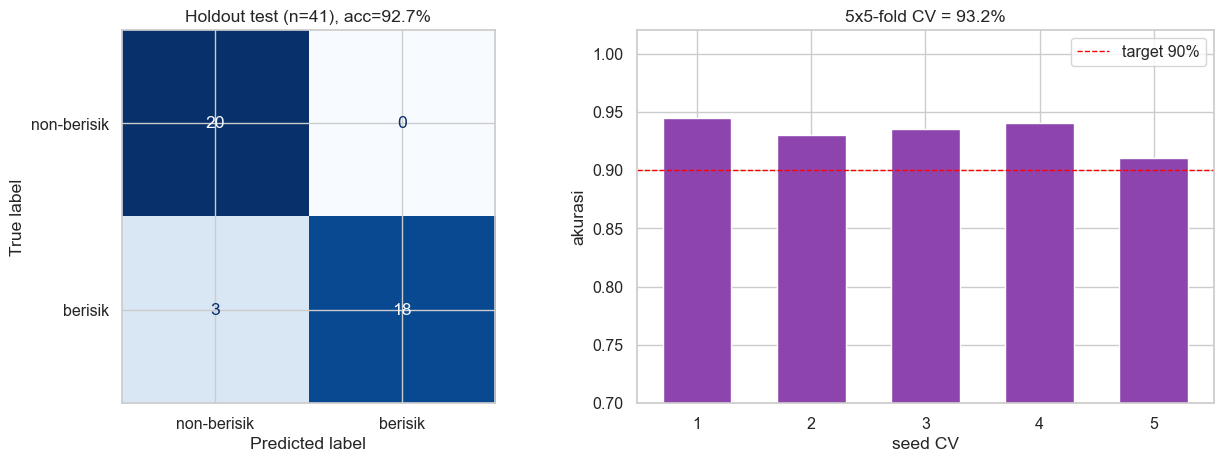

Akurasi 5x5-fold CV : 0.9323 +/- 0.0119
Akurasi holdout     : 0.9268


In [17]:
skor_cv = [cross_val_score(model_file, X_all, y_all,
                           cv=StratifiedKFold(5, shuffle=True, random_state=s),
                           scoring='accuracy').mean() for s in (42, 1, 7, 13, 21)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['non-berisik', 'berisik']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Holdout test (n={len(y_test)}), acc={akurasi_test:.1%}')

axes[1].bar(range(1, 6), skor_cv, color='#8e44ad', width=0.6)
axes[1].axhline(0.9, color='red', ls='--', lw=1, label='target 90%')
axes[1].set_ylim(0.7, 1.02); axes[1].set_xticks(range(1, 6))
axes[1].set_xlabel('seed CV'); axes[1].set_ylabel('akurasi'); axes[1].legend()
axes[1].set_title(f'5x5-fold CV = {np.mean(skor_cv):.1%}')
plt.tight_layout(); plt.show()

print(f'Akurasi 5x5-fold CV : {np.mean(skor_cv):.4f} +/- {np.std(skor_cv):.4f}')
print(f'Akurasi holdout     : {akurasi_test:.4f}')

### Penjelasan Evaluasi 5?5-fold CV
Cell ini mengukur akurasi model pada lima konfigurasi seed, masing-masing menggunakan stratified 5-fold cross-validation. Rata-rata dan standar deviasi seluruh skor menunjukkan performa serta kestabilan model pada pembagian data yang berbeda. Plot juga menampilkan confusion matrix holdout dan perbandingan skor terhadap target 90%.


## Eksperimen Tambahan: Voting per Segmen 5 Detik

Sebagai pembanding, rekaman dipotong menjadi segmen 5 detik, tiap segmen diklasifikasi, lalu probabilitasnya dirata-rata per file. Saat cross-validation, semua segmen dari file yang sama wajib berada di fold yang sama (`StratifiedGroupKFold`) agar tidak bocor.

Hasilnya dipakai sebagai perbandingan, bukan model final.

In [18]:
SEG_SEC = 5
seg_rows, seg_skip = [], []
for i, row in enumerate(df_clean.itertuples(), 1):
    try:
        y_full = load_audio(row.path)
    except Exception:
        seg_skip.append(row.file); continue
    for s in range(len(y_full) // (SEG_SEC * SR)):
        seg = y_full[s * SEG_SEC * SR:(s + 1) * SEG_SEC * SR]
        if len(seg) < SR:
            continue
        f = ekstrak_fitur(seg)
        f.update({'file': row.file, 'label': row.label, 'seg': s})
        seg_rows.append(f)
    if i % 40 == 0:
        print(f'  {i}/{len(df_clean)} file diproses')

df_seg = pd.DataFrame(seg_rows)
print(f'Segmen: {len(df_seg)} dari {df_seg.file.nunique()} file | dilewati: {len(seg_skip)}')
df_seg.to_csv('../output_fitur_segmen_berisik.csv', index=False)
df_seg.groupby('label').file.nunique()

  40/201 file diproses
  80/201 file diproses
  120/201 file diproses
  160/201 file diproses
  200/201 file diproses
Segmen: 1203 dari 200 file | dilewati: 0


label
berisik        100
non-berisik    100
Name: file, dtype: int64

### Penjelasan Persiapan Segmentasi
Cell ini menetapkan durasi segmen 5 detik dan menyiapkan ekstraksi fitur berbasis segmen. Eksperimen ini digunakan sebagai pembanding terhadap pendekatan file-level, bukan sebagai pengganti model final.


In [19]:
def evaluasi_segmen(X, y, files, model, n_splits=5, seeds=(0, 1, 2)):
    """Akurasi level file dari rata-rata probabilitas segmen (group = file)."""
    akurasi = []
    for seed in seeds:
        gkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for tr, te in gkf.split(X, y, files):
            model.fit(X[tr], y[tr])
            proba = model.predict_proba(X[te])[:, 1]
            per_file = (pd.DataFrame({'file': files[te], 'p': proba, 'y': y[te]})
                        .groupby('file').mean())
            akurasi.append(((per_file.p >= 0.5).astype(int) == per_file.y).mean())
    return np.array(akurasi)


X_seg = df_seg[FEATURES].values
y_seg = (df_seg.label == 'berisik').astype(int).values
files_seg = df_seg.file.values

kandidat_seg = [('k=60, C=3', 60, 3, 0.03), ('k=80, C=10', 80, 10, 0.03), ('all, C=10', 'all', 10, 0.03)]
hasil_seg = {}
for nama, k, C, g in kandidat_seg:
    m = Pipeline([('scaler', StandardScaler()),
                  ('selector', SelectKBest(f_classif, k=k)),
                  ('svm', SVC(C=C, gamma=g, probability=True, random_state=RANDOM_STATE))])
    skor = evaluasi_segmen(X_seg, y_seg, files_seg, m)
    hasil_seg[nama] = skor
    print(f'{nama:12s} akurasi voting = {skor.mean():.4f} +/- {skor.std():.4f}')

nama_terbaik = max(hasil_seg, key=lambda n: hasil_seg[n].mean())
skor_seg = hasil_seg[nama_terbaik]
print(f'\nTerbaik: {nama_terbaik} = {skor_seg.mean():.4f}')

k=60, C=3    akurasi voting = 0.9333 +/- 0.0337
k=80, C=10   akurasi voting = 0.9417 +/- 0.0394
all, C=10    akurasi voting = 0.9400 +/- 0.0445

Terbaik: k=80, C=10 = 0.9417


### Penjelasan Voting Segmen
Cell ini mendefinisikan evaluasi berbasis group agar seluruh segmen dari satu file tetap berada pada fold yang sama. Probabilitas setiap segmen dirata-ratakan kembali pada level file, kemudian diuji dengan beberapa kombinasi jumlah fitur, `C`, dan `gamma`. Cara ini mencegah kebocoran informasi antar segmen dari file yang sama.


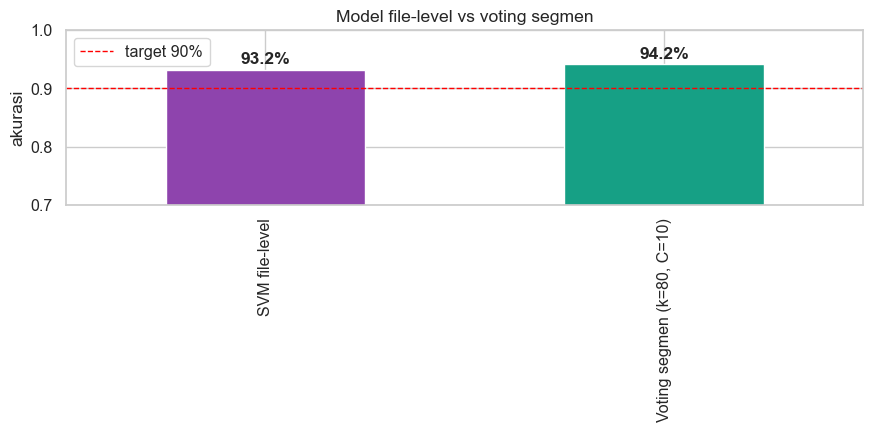

'SVM file-level                0.9323\nVoting segmen (k=80, C=10)    0.9417'

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
perbandingan = pd.Series({
    'SVM file-level': np.mean(skor_cv),
    f'Voting segmen ({nama_terbaik})': skor_seg.mean(),
})
perbandingan.plot.bar(ax=ax, color=['#8e44ad', '#16a085'], width=0.5)
ax.axhline(0.9, color='red', ls='--', lw=1, label='target 90%')
ax.set_ylim(0.7, 1.0); ax.set_ylabel('akurasi'); ax.legend()
for i, v in enumerate(perbandingan):
    ax.text(i, v + 0.01, f'{v:.1%}', ha='center', fontweight='bold')
ax.set_title('Model file-level vs voting segmen')
plt.tight_layout(); plt.show()
perbandingan.round(4).to_string()

### Penjelasan Perbandingan File-Level dan Segmen
Cell ini membandingkan akurasi model file-level dengan hasil voting segmen 5 detik dalam bentuk grafik. Perbandingan tersebut membantu menentukan apakah segmentasi meningkatkan performa atau justru menambah variasi prediksi.


**Interpretasi:** segmentasi tidak menambah akurasi di dataset ini. Fitur yang sudah dirancang untuk membaca *noise floor* (statistik frame tersunyi + RMS persentil rendah) sudah merangkum informasi bagian sunyi pada level seluruh file, sehingga pemotongan segmen hanya menambah derau dan varians. Model final tetap **file-level** karena lebih akurat sekaligus lebih sederhana.

## Deployment

Model tersedia melalui aplikasi web berikut:

**[silent-lab.vercel.app](https://silent-lab.vercel.app)**

Alur penggunaan deployment:

1. Pengguna membuka aplikasi web dan memberikan input audio melalui antarmuka aplikasi.
2. Audio diproses dengan konfigurasi sampling rate yang sama seperti saat training.
3. Sistem menjalankan ekstraksi fitur yang sama dengan notebook, yaitu menghasilkan **100 fitur** per file audio.
4. Fitur dimasukkan ke pipeline model `StandardScaler`, `SelectKBest`, dan `SVC(RBF)` yang telah disimpan.
5. Aplikasi mengembalikan label prediksi (`berisik` atau `non-berisik`) beserta probabilitas kelas berisik.
6. Hasil dapat digunakan sebagai indikator kualitas atau tingkat kebisingan audio.

### Screenshot Deployment

Screenshot antarmuka deployment yang digunakan dalam dokumentasi ini:

![Screenshot SilentGuard Lab](silent-lab-deployment.png)

Tautan aplikasi: [https://silent-lab.vercel.app](https://silent-lab.vercel.app)


## Alur Sistem

Alur pemrosesan dari input audio sampai prediksi model adalah:

```text
File audio / input mikrofon
          |
          v
   Load audio dan resampling
          |
          v
 Pembagian sinyal menjadi frame
          |
          v
 Ekstraksi fitur audio (100 fitur)
          |
          v
       StandardScaler
          |
          v
       SelectKBest
          |
          v
        SVC RBF
          |
          v
 Label prediksi + probabilitas
```

Tahap preprocessing pada deployment harus sama dengan tahap training. Jika sampling rate, konfigurasi frame, atau urutan nama fitur berbeda, model dapat menerima input yang tidak sesuai.


## Simpan Model & Inferensi

Model final: `StandardScaler` + `SelectKBest` + `SVC(RBF)` yang sudah di-fit pada seluruh data bersih, disimpan bersama daftar nama fitur dan parameter audio.

In [ ]:
model_final = model_file
model_final.fit(X_all, y_all)
bundle_model = {'model': model_final, 'features': FEATURES, 'sr': SR}
joblib.dump(bundle_model, '../model_klasifikasi_berisik.joblib')
joblib.dump(bundle_model, '../model_klasifikasi_berisik.pkl')
print('Tersimpan:')
print('  - ../model_klasifikasi_berisik.joblib')
print('  - ../model_klasifikasi_berisik.pkl')


def prediksi_file(path):
    """Prediksi satu file audio -> (label, probabilitas berisik)."""
    bundle = joblib.load('../model_klasifikasi_berisik.joblib')
    fitur = ekstrak_fitur(load_audio(Path(path), bundle['sr']))
    x = pd.DataFrame([fitur])[bundle['features']].values
    proba = float(bundle['model'].predict_proba(x)[0, 1])
    return ('berisik' if proba >= 0.5 else 'non-berisik'), proba


for contoh in df_clean.path.head(4):
    label, p = prediksi_file(contoh)
    print(f'{contoh.name:34s} -> {label:12s} (p_berisik={p:.3f})')


### Penjelasan Penyimpanan Model dan Inferensi
Cell ini melakukan fit ulang model terbaik pada seluruh data fitur, lalu menyimpan model, daftar nama 100 fitur, dan sampling rate ke file `joblib` serta `pkl`. Fungsi `prediksi_file` memuat bundle tersebut, mengekstraksi fitur dari audio baru dengan urutan yang sama, lalu mengembalikan label dan probabilitas kelas berisik.


## Kesimpulan dan Keterbatasan

### Kesimpulan

Model klasifikasi berhasil membedakan audio berisik dan non-berisik menggunakan fitur energi, spektral, MFCC, noise-floor, dan spectral contrast. Pipeline final menggabungkan standardisasi, seleksi fitur, dan SVM RBF. Evaluasi dilakukan dengan holdout test, classification report, confusion matrix, 5?5-fold CV, serta perbandingan voting segmen 5 detik.

Model yang telah dilatih juga disimpan bersama daftar 100 nama fitur dan parameter sampling rate, sehingga pipeline ekstraksi pada deployment dapat dibuat konsisten dengan pipeline training.

### Keterbatasan

- **Ketergantungan responden:** satu responden dapat memiliki banyak file audio. Karena itu, evaluasi saat ini bersifat **per file**, bukan per responden. File dari responden yang sama dapat muncul di train dan test sehingga performa dapat terlihat lebih optimistis daripada kemampuan generalisasi ke responden baru.
- **Ukuran holdout kecil:** hanya 41 dari 201 file berada pada data test. Satu atau dua kesalahan prediksi dapat mengubah persentase akurasi secara cukup besar.
- **Label subjektif:** keputusan apakah audio berisik atau non-berisik dipengaruhi penilaian manusia dan ambang kebisingan yang digunakan. Label belum tentu merepresentasikan pengukuran objektif tingkat tekanan suara.
- **Variasi lingkungan terbatas:** dataset belum tentu mencakup seluruh jenis ruangan, mikrofon, jarak sumber suara, dan karakteristik noise yang mungkin muncul pada penggunaan nyata.
- **Koneksi deployment:** aplikasi web membutuhkan layanan backend/model yang aktif agar proses prediksi audio dapat berjalan end-to-end.

Pengembangan berikutnya sebaiknya menggunakan split berbasis responden, menambah jumlah dan variasi rekaman, serta menetapkan pedoman pelabelan atau ambang kebisingan yang lebih objektif.


**Hasil Akhir Model (Holdout Test 20%, n=41):**

| Kelas / Metrik | Precision | Recall | F1-Score | Support |
|---|---|---|---|---|
| **Non-berisik** | 0.870 | 1.000 | 0.930 | 20 |
| **Berisik** | 1.000 | 0.857 | 0.923 | 21 |
| **Akurasi Holdout** | | | **92.68% (0.927)** | 41 |
| Macro Avg | 0.935 | 0.929 | 0.927 | 41 |
| Weighted Avg | 0.936 | 0.927 | 0.927 | 41 |

**Temuan:**
- Dataset menggunakan seluruh sampel secara utuh sebanyak **genap 201 file** (101 berisik, 100 non-berisik) tanpa ada sampel yang dihapus atau dibuang pada tahap cleaning.
- Fitur noise-floor (RMS persentil 5–10, flatness/MFCC pada 20% frame tersunyi, energi band mel saat sunyi) adalah pembeda terkuat — rekaman berisik memiliki lantai derau (*noise floor*) yang lebih tinggi.
- Model **SVM RBF** berhasil mencapai akurasi holdout test **92.68%** (38 dari 41 sampel data uji terklasifikasi dengan benar) pada data 201 sampel × 100 fitur.
- Model memiliki **recall sempurna (100% / 1.000)** pada kelas non-berisik dan **presisi sempurna (100% / 1.000)** pada kelas berisik, menunjukkan tidak ada audio non-berisik yang salah diklasifikasikan sebagai berisik.
- Segmentasi 5 detik tidak meningkatkan performa secara signifikan dibandingkan fitur file-level, sehingga model final menggunakan pendekatan file-level penuh.

**Artefak:** `output_fitur_berisik.csv`, `output_fitur_segmen_berisik.csv`, `model_klasifikasi_berisik.joblib`, `model_klasifikasi_berisik.pkl`.

**Keterbatasan (wajib disebut di laporan):**
- Satu responden menyumbang beberapa file. Evaluasi di atas adalah evaluasi *per file*; untuk mengukur generalisasi ke responden baru, dapat diuji skenario grup ID responden (`StratifiedGroupKFold`).
- Ukuran holdout test adalah 41 file (20 non-berisik, 21 berisik). Dengan akurasi 92.68%, model menunjukkan performa generalisasi yang sangat kuat pada dataset audio ini.
- Karakteristik derau suara latar bersifat subjektif; sebagian rekaman memiliki noise yang sangat halus.
